In [63]:
from pathlib import Path
import copy
import json
import platform
import time
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
from matplotlib.animation import FuncAnimation
from IPython.display import HTML, display
import sklearn
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
import torch
from torch import nn
torch.set_num_threads(2)
torch.manual_seed(42)
np.random.seed(42)
ROOT = Path.cwd()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if not (ROOT / 'visuals').exists():
    ROOT = ROOT / 'optimizer_step_pytorch_episode_03'
for folder in ['visuals', 'animations/generated_training_animations', 'validation']:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)
COLORS = ['#2589d8', '#ef8d32']
cmap = ListedColormap(COLORS)
plt.rcParams.update({'figure.dpi': 110, 'font.size': 12, 'axes.spines.top': False, 'axes.spines.right': False})
versions = {'python': platform.python_version(), 'torch': torch.__version__, 'numpy': np.__version__, 'matplotlib': matplotlib.__version__, 'sklearn': sklearn.__version__, 'platform': platform.platform(), 'device': 'cpu', 'threads': torch.get_num_threads()}
print(json.dumps(versions, indent=2))
started = time.perf_counter()
results = {}

{
  "python": "3.12.13",
  "torch": "2.13.0+cu130",
  "numpy": "2.5.2",
  "matplotlib": "3.11.0",
  "sklearn": "1.7.2",
  "platform": "Windows-11-10.0.26200-SP0",
  "device": "cpu",
  "threads": 2
}


In [8]:
def plot_boundary(model, X, y, title=''):
    X, y = np.asarray(X), np.asarray(y).ravel()
    xx, yy = np.meshgrid(np.linspace(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5, 200),
                         np.linspace(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5, 200))
    grid = torch.tensor(np.c_[xx.ravel(), yy.ravel()], dtype=torch.float32)
    with torch.no_grad():
        z = model(grid).reshape(xx.shape).numpy()
    plt.contourf(xx, yy, z > 0, alpha=0.3, cmap='coolwarm')
    plt.scatter(X[:, 0], X[:, 1], c=y, cmap='coolwarm', s=10)
    plt.title(title)
    plt.show()
def accuracy(model, X, y):
    with torch.no_grad():
        return ((model(X) > 0).float() == y).float().mean().item()

C:\Users\AIML\AppData\Local\Temp\ipykernel_14384\189100453.py:4: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_train = torch.tensor(X_train, dtype = torch.float32)
C:\Users\AIML\AppData\Local\Temp\ipykernel_14384\189100453.py:5: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  X_test = torch.tensor(X_test, dtype=torch.float32)
C:\Users\AIML\AppData\Local\Temp\ipykernel_14384\189100453.py:6: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  y_train = torch.tensor(y_train, dtype = torch.float32).reshape(-1,1)
C:\Users\AIML\AppData\Local\Temp\ipy

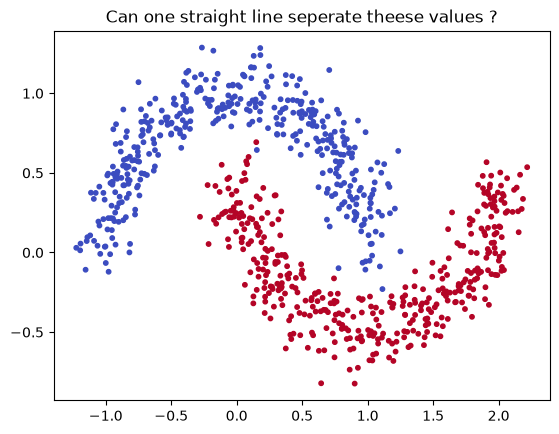

torch.Size([600, 2]) torch.Size([600, 1])


In [29]:
X, y = make_moons(n_samples = 800, noise = 0.12, random_state=42)
X_train_np, X_test_np, y_train_np, y_test_np = train_test_split(X, y, test_size=0.25, random_state=42, stratify = y)

X_train = torch.tensor(X_train, dtype = torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
y_train = torch.tensor(y_train, dtype = torch.float32).reshape(-1,1)

y_test = torch.tensor(y_test, dtype = torch.float32).reshape(-1,1)
plt.scatter(X[:,0], X[:,1], c = y, cmap = 'coolwarm', s = 10)
plt.title("Can one straight line seperate theese values ?")
plt.show()
print(X_train.shape, y_train.shape)

In [14]:
neuron = nn.Linear(2,1)
with torch.no_grad():
    neuron.weight.copy_(torch.tensor([[1.5, 2.0]]))
    neuron.bias.copy_(torch.tensor([1.0]))

human_inputs = torch.tensor([[2.0, -3.0], [2.0, 1.0]])
human_scores = neuron(human_inputs)
print("Raw scores: ", human_scores.detach().flatten().tolist())


Raw scores:  [-2.0, 6.0]


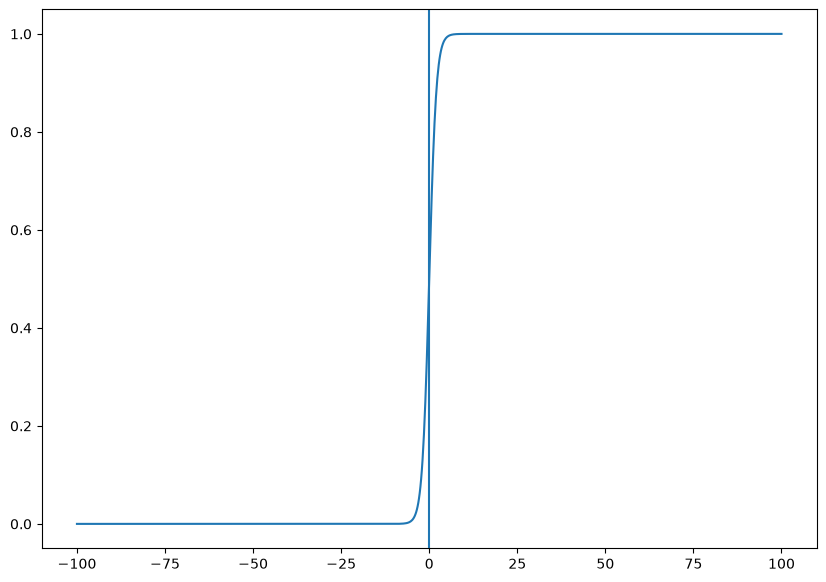

In [18]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

x = np.linspace(-100, 100, 1000)
y = sigmoid(x)

plt.figure(figsize = (10,7))
plt.plot(x, y)
plt.axvline(0)

In [20]:
scores = torch.tensor([[-2.0], [0.0], [2.0]])
probabilities = torch.sigmoid(scores)
targets = torch.tensor([[0.0], [1.0], [1.0]])
loss_functions = nn.BCEWithLogitsLoss()
print("Probabilities: ", probabilities.flatten().tolist())
print("Mean loss: ", loss_functions(scores, targets).item())
print("Classes: ", (scores >= 0).int().flatten().tolist())

Probabilities:  [0.11920291930437088, 0.5, 0.8807970285415649]
Mean loss:  0.3156677782535553
Classes:  [0, 1, 1]


In [21]:
w = torch.tensor(1.0, requires_grad=True)
practice_loss = (w - 3.0) ** 2
practice_loss.backward()
print("Loss: ", practice_loss.item(), "Gradient: ", w.grad.item())
with torch.no_grad():
    w -= 0.1 *w.grad

print("Updated w: ", w.item())


Loss:  4.0 Gradient:  -4.0
Updated w:  1.399999976158142


lr = 0.01: [4.0, 3.842, 3.689, 3.543, 3.403, 3.268, 3.139, 3.015]
lr = 0.1: [4.0, 2.56, 1.638, 1.049, 0.671, 0.429, 0.275, 0.176]
lr = 1.1: [4.0, 5.76, 8.294, 11.944, 17.199, 24.767, 35.664, 51.357]


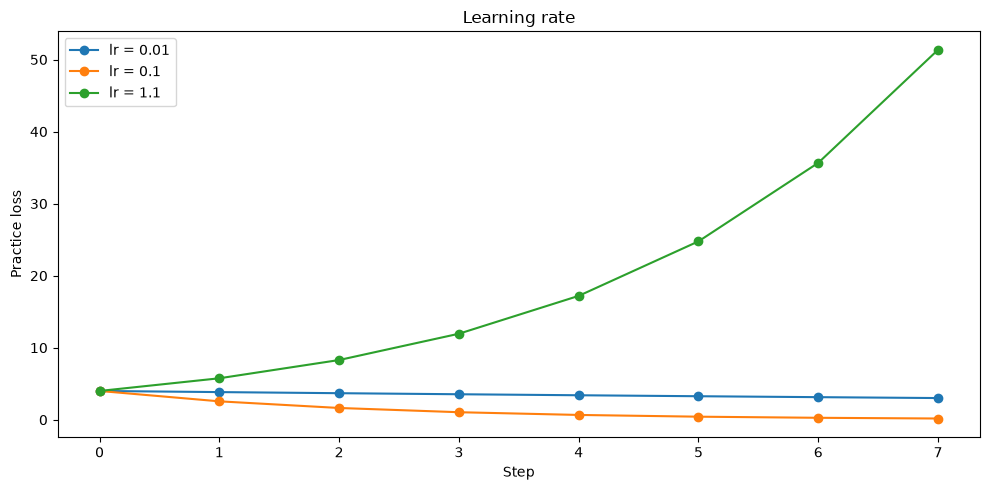

In [24]:
rate_paths = {}
for rate in [0.01, 0.1, 1.1]:
    w = torch.tensor(1.0, requires_grad=True)
    losses = []
    for _ in range(8):
        loss = (w - 3.0) ** 2
        losses.append(round(loss.item(), 3))
        loss.backward()
        with torch.no_grad():
            w -= rate * w.grad
        w.grad.zero_()
    rate_paths[rate] = losses

    print(f"lr = {rate}:", losses)

fig, ax = plt.subplots(figsize = (10, 5))
for rate, losses in rate_paths.items():
    ax.plot(range(8), losses, marker = 'o', label = f"lr = {rate}")
ax.set(xlabel = 'Step', ylabel = 'Practice loss', title = 'Learning rate')
ax.legend()
fig.tight_layout()
plt.show()

In [27]:
w = torch.tensor(1.0, requires_grad=True)
optimizer = torch.optim.SGD([w], lr = 0.1)
loss = (w - 3.0) ** 2
loss.backward()
optimizer.step()
print("After optimizer.step(): w = ", round(w.item(), 4))
optimizer.zero_grad()
for call in range(2):
    ((w - 3.0) ** 2).backward()
    print(f"After backward call {call + 1}: w.grad = ", round(w.grad.item(), 3))
    optimizer.zero_grad()

optimizer.zero_grad()
print("after zero_grad(): w.grad = ", w.grad)


After optimizer.step(): w =  1.4
After backward call 1: w.grad =  -3.2
After backward call 2: w.grad =  -3.2
after zero_grad(): w.grad =  None


In [34]:
gx, gy = np.meshgrid(np.linspace(-1.8, 2.8, 100), np.linspace(-1.3, 1.8, 100))
grid = torch.tensor(np.column_stack([gx.ravel(), gy.ravel()]), dtype=torch.float32)
def boundary(ax, model, points, labels, title, mesh=(gx, gy), query=grid):
    model.eval()
    with torch.no_grad():
        z = model(query).reshape(mesh[0].shape).numpy()
    p = 1 / (1 + np.exp(-np.clip(z, -60, 60)))
    ax.contourf(*mesh, p, levels=np.linspace(0, 1, 21), cmap='RdBu_r', alpha=0.32)
    if z.min() < 0 < z.max():
        ax.contour(*mesh, z, levels=[0], colors='#18243a', linewidths=2)
    ax.scatter(points[:, 0], points[:, 1], c=labels, cmap='coolwarm', s=12, edgecolors='white', linewidths=0.2)
    ax.set(title=title, xlabel='First coordinate', ylabel='Second coordinate')
    ax.set_aspect('equal')
    return z
def metrics(model, inputs, targets):
    model.eval()
    with torch.no_grad():
        z = model(inputs)
        loss = loss_function(z, targets).item()
        accuracy = ((z >= 0) == (targets >= 0.5)).float().mean().item()
    return {'loss': loss, 'accuracy': accuracy}

{
  "train": {
    "loss": 0.28251326084136963,
    "accuracy": 0.8533333539962769
  },
  "test": {
    "loss": 0.23633629083633423,
    "accuracy": 0.9049999713897705
  }
}


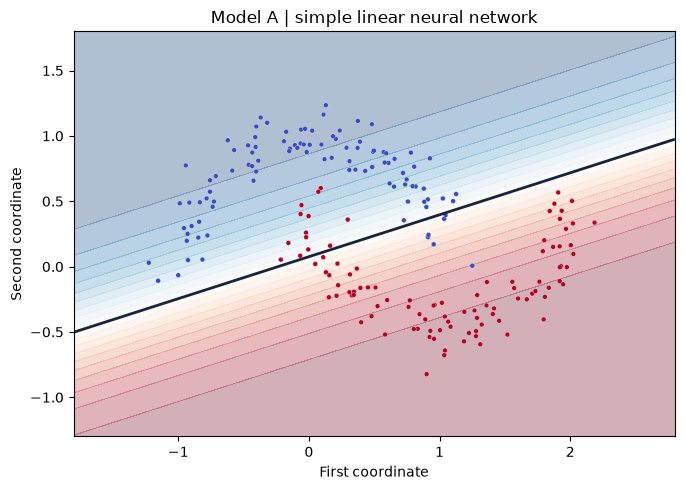

In [37]:
import json
torch.manual_seed(42)
results = {}
loss_function = nn.BCEWithLogitsLoss()
model_a = nn.Linear(2,1)
optimizer = torch.optim.SGD(model_a.parameters(), lr = 0.1)
loss_a = []
for epoch in range(900):
    model_a.train()
    optimizer.zero_grad()
    predictions = model_a(X_train)
    loss = loss_function(predictions, y_train)
    loss.backward()
    optimizer.step()
    loss_a.append(loss.item())
results['A'] = {'train': metrics(model_a, X_train, y_train), 'test': metrics(model_a, X_test, y_test)}
print(json.dumps(results['A'], indent = 2))
fig, ax = plt.subplots(figsize = (8,5))
boundary(ax, model_a, X_test_np, y_test_np, 'Model A | simple linear neural network')
fig.tight_layout()
plt.show()


In [41]:
def fit(model, optimizer, inputs, targets, epochs = 600, query = grid):
    history, frames, frame_epochs = [], [], []
    checkpoints = set(np.linspace(0, epochs, 41, dtype = int))
    for epoch in range(epochs + 1):
        if query is not None and epoch in checkpoints:
            model.eval()
            with torch.no_grad():
                frames.append(model(query).detach().numpy().copy())
            frame_epochs.append(epoch)
        if epoch == epochs:
            break
        model.train()
        optimizer.zero_grad()
        scores = model(inputs)
        loss = loss_function(scores, targets)
        loss.backward()
        optimizer.step()
        history.append(loss.item())
    return {"loss" : history, "frames": frames, "epochs": frame_epochs}
    

In [42]:
torch.manual_seed(42)
model_b = nn.Sequential(nn.Linear(2,16), nn.Linear(16,16), nn.Linear(16, 1))
optimizer_b = torch.optim.SGD(model_b.parameters(), lr = 0.1)
trace_b = fit(model_b, optimizer_b, X_train, y_train)
results['B'] = {"train": metrics(model_b, X_train, y_train), "test": metrics(model_b, X_test, y_test)}
with torch.no_grad():
    effective_w = model_b[2].weight @ model_b[1].weight @ model_b[0].weight
    effective_b = model_b[2].weight @ (model_b[1].weight @ model_b[0].bias + model_b[1].bias) + model_b[2].bias
    collapsed = X_test @ effective_w.T + effective_b
    error = (collapsed - model_b(X_test)).abs().max().item()

print("Maximum collapse error:", error, '\n', results["B"])

Maximum collapse error: 9.5367431640625e-07 
 {'train': {'loss': 0.2644152343273163, 'accuracy': 0.8733333349227905}, 'test': {'loss': 0.2087303102016449, 'accuracy': 0.9200000166893005}}


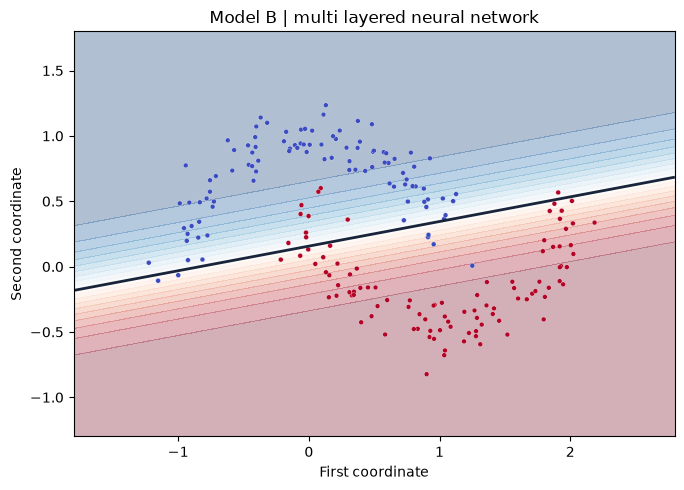

In [43]:
fig, ax = plt.subplots(figsize =( 8,5))
boundary(ax, model_b, X_test_np, y_test_np, "Model B | multi layered neural network")
fig.tight_layout()
plt.show()

Human neuron after ReLU:  [0.0, 6.0]


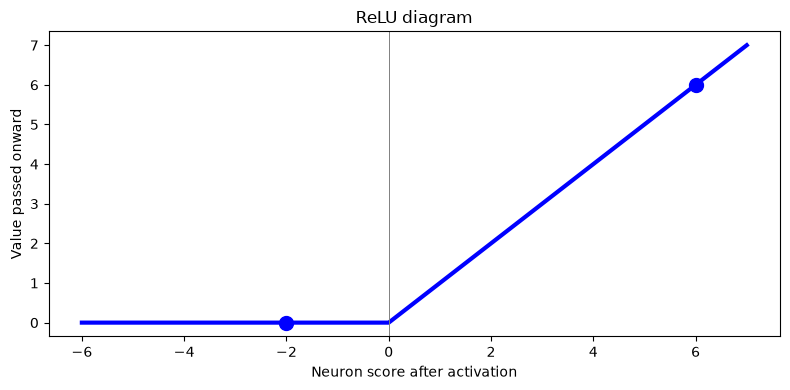

In [45]:
relu = nn.ReLU()
print("Human neuron after ReLU: ", relu(human_scores).detach().flatten(). tolist())
t = torch.linspace(-6, 7, 300)
fig, ax = plt.subplots(figsize = (8,4))
ax.plot(t, relu(t), color = 'blue', lw = 3)
ax.scatter([-2, 6], [0,6], c = 'blue', s = 100, zorder = 3)
ax.axvline(0, color = 'gray', lw = 0.7)
ax.set(xlabel = 'Neuron score after activation', ylabel = 'Value passed onward', title = 'ReLU diagram')
fig.tight_layout()
plt.show()


{
  "train": {
    "loss": 0.21320781111717224,
    "accuracy": 0.9066666960716248
  },
  "test": {
    "loss": 0.16165250539779663,
    "accuracy": 0.9300000071525574
  }
}


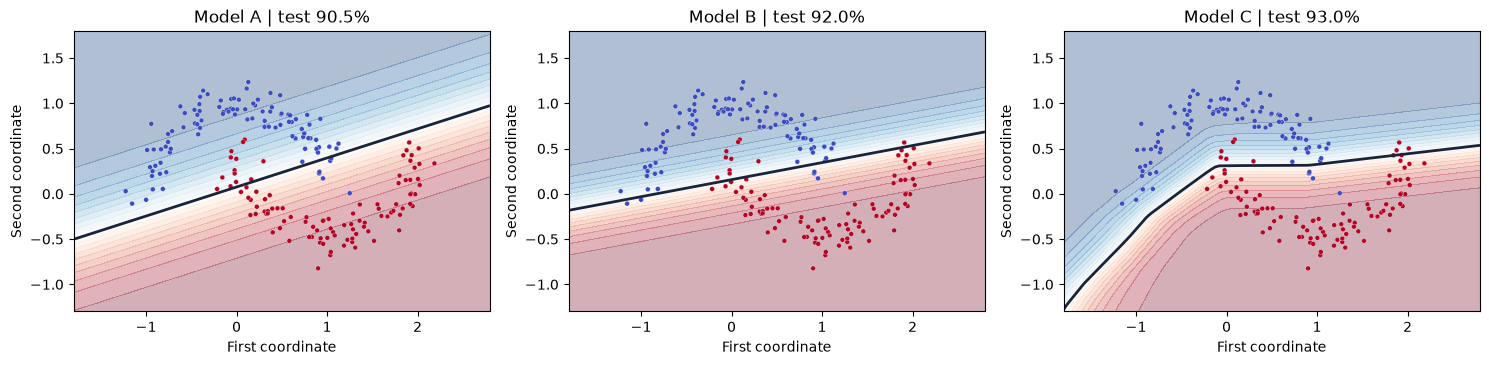

In [47]:
torch.manual_seed(42)
model_c = nn.Sequential(nn.Linear(2, 16), nn.ReLU(), nn.Linear(16, 16), nn.ReLU(), nn.Linear(16,1))
with torch.no_grad():
    torch.manual_seed(42)
    initial_b = nn.Sequential(nn.Linear(2,16), nn.Linear(16, 16), nn.Linear(16,1))
    for c_index, b_index in [(0,0), (2,1), (4,2)]:
        model_c[c_index].load_state_dict(initial_b[b_index].state_dict())

trace_c = fit(model_c, torch.optim.SGD(model_c.parameters(), lr = 0.1), X_train, y_train)
results['C'] = {'train': metrics(model_c, X_train, y_train),
                'test': metrics(model_c, X_test, y_test)}
print(json.dumps(results['C'], indent = 2))
fig, axes = plt.subplots(1,3, figsize = (15,4))
for ax, name, model in zip(axes, ['A', 'B', 'C'], [model_a, model_b, model_c]):
    boundary(ax, model, X_test_np, y_test_np, f"Model {name} | test {results[name]['test']['accuracy']:.1%}")

fig.tight_layout()
plt.show()

In [49]:
from matplotlib.animation import FuncAnimation

Animation unavailable; use static snapshots: name 'cmap' is not defined


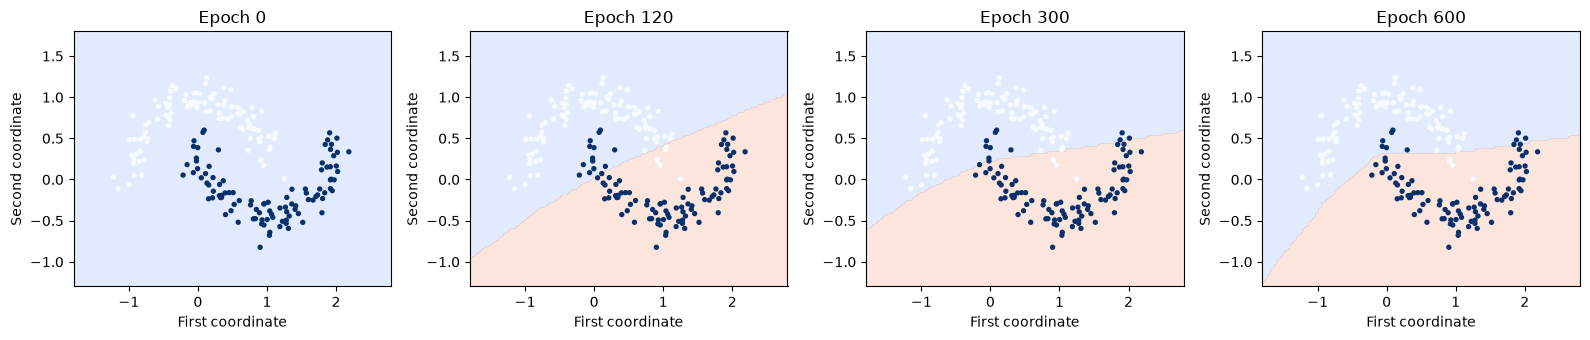

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
def draw_frame(index):
    axes[0].clear()
    axes[1].clear()
    z = trace_c['frames'][index].reshape(gx.shape)
    epoch = trace_c['epochs'][index]
    axes[0].contourf(gx, gy, z >= 0, levels=[-0.5, 0.5, 1.5], cmap=cmap, alpha=0.25)
    axes[0].scatter(X_test_np[:, 0], X_test_np[:, 1], c=y_test_np, cmap=cmap, s=12)
    axes[0].set(title=f'Model C | epoch {epoch}', xlabel='First coordinate', ylabel='Second coordinate')
    axes[1].plot(np.arange(1, epoch + 1), trace_c['loss'][:epoch], color='#18243a')
    axes[1].set(xlim=(0, 600), ylim=(0, max(trace_c['loss']) * 1.05), xlabel='Update (pre-update loss)', ylabel='Binary cross entropy', title='Learning history')
    fig.tight_layout()
animation = FuncAnimation(fig, draw_frame, frames=len(trace_c['frames']), interval=160, repeat=False)
try:
    animation_html = animation.to_jshtml(fps=6)
    (ROOT / 'animations/generated_training_animations/model_c.html').write_text(animation_html, encoding='utf8')
    display(HTML(animation_html))
except Exception as animation_error:
    print('Animation unavailable; use static snapshots:', animation_error)
plt.close(fig)
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5))
for ax, index in zip(axes, [0, 8, 20, 40]):
    z = trace_c['frames'][index].reshape(gx.shape)
    ax.contourf(gx, gy, z >= 0, levels=[-0.5, 0.5, 1.5], cmap='coolwarm', alpha=0.25)
    ax.scatter(X_test_np[:, 0], X_test_np[:, 1], c=y_test_np, cmap='Blues', s=8)
    ax.set(title=f"Epoch {trace_c['epochs'][index]}", xlabel='First coordinate', ylabel='Second coordinate')
fig.tight_layout()

plt.show()

width_8 {'parameters': 105, 'train': {'loss': 0.004356996156275272, 'accuracy': 0.996666669845581}, 'test': {'loss': 0.0021675308234989643, 'accuracy': 1.0}}
width_16 {'parameters': 337, 'train': {'loss': 0.004555550403892994, 'accuracy': 0.996666669845581}, 'test': {'loss': 0.0015528331277891994, 'accuracy': 1.0}}
width_64 {'parameters': 4417, 'train': {'loss': 0.00034385742037557065, 'accuracy': 1.0}, 'test': {'loss': 0.00029308232478797436, 'accuracy': 1.0}}


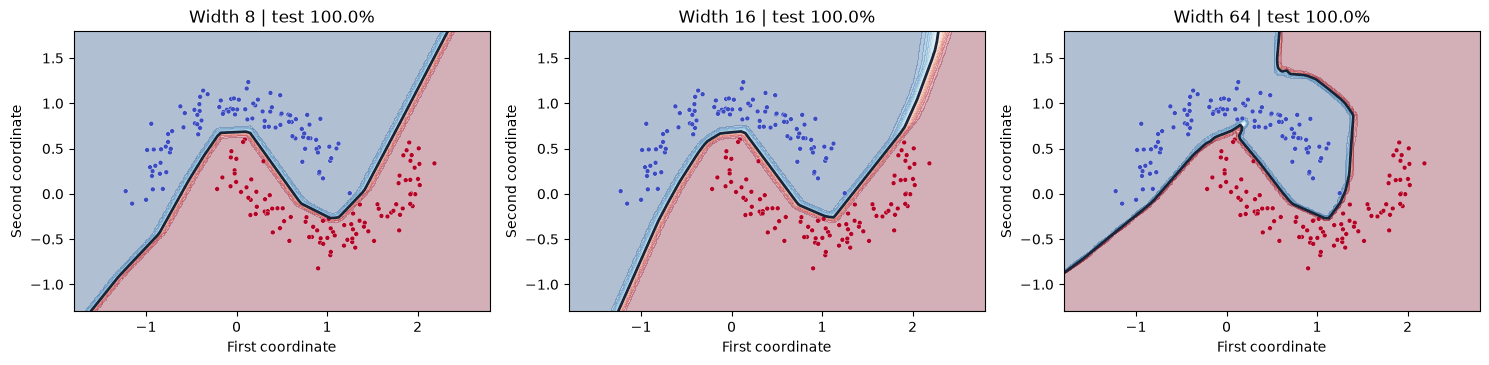

In [55]:
def make_network(width=16, activation=nn.ReLU):
    return nn.Sequential(nn.Linear(2, width), activation(), nn.Linear(width, width), activation(), nn.Linear(width, 1))
capacity_models = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, width in zip(axes, [8, 16, 64]):
    torch.manual_seed(101)
    model = make_network(width)
    trace = fit(model, torch.optim.Adam(model.parameters(), lr=0.01), X_train, y_train, epochs=700, query=None)
    capacity_models[width] = model
    name = f'width_{width}'
    results[name] = {'parameters': sum(p.numel() for p in model.parameters()), 'train': metrics(model, X_train, y_train), 'test': metrics(model, X_test, y_test)}
    boundary(ax, model, X_test_np, y_test_np, f"Width {width} | test {results[name]['test']['accuracy']:.1%}")
    print(name, results[name])
fig.tight_layout()

plt.show()

In [59]:
import numpy as np
import copy

ReLU {'train': {'loss': 0.00492711691185832, 'accuracy': 0.996666669845581}, 'test': {'loss': 0.0014392377343028784, 'accuracy': 1.0}}
Tanh {'train': {'loss': 0.005573079455643892, 'accuracy': 0.996666669845581}, 'test': {'loss': 0.004623276647180319, 'accuracy': 1.0}}


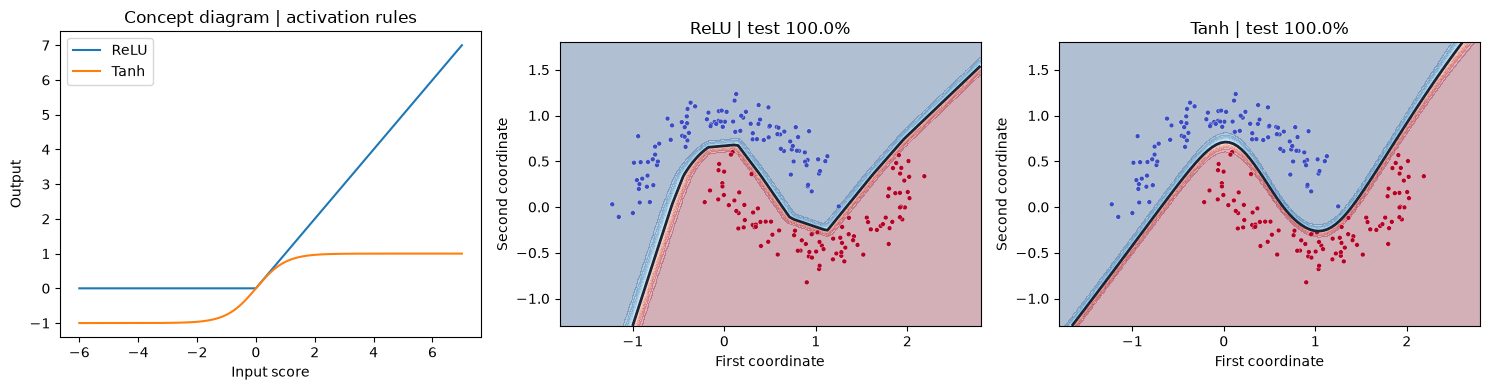

In [60]:
torch.manual_seed(202)
common_state = copy.deepcopy(make_network(16).state_dict())
activation_models = {}
activation_traces = {}
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(t, torch.relu(t), label='ReLU')
axes[0].plot(t, torch.tanh(t), label='Tanh')
axes[0].set(title='Concept diagram | activation rules', xlabel='Input score', ylabel='Output')
axes[0].legend()
for ax, name, activation in zip(axes[1:], ['ReLU', 'Tanh'], [nn.ReLU, nn.Tanh]):
    model = make_network(16, activation)
    model.load_state_dict(common_state)
    activation_traces[name] = fit(model, torch.optim.Adam(model.parameters(), lr=0.01), X_train, y_train, epochs=700)
    activation_models[name] = model
    results[name] = {'train': metrics(model, X_train, y_train), 'test': metrics(model, X_test, y_test)}
    boundary(ax, model, X_test_np, y_test_np, f"{name} | test {results[name]['test']['accuracy']:.1%}")
    print(name, results[name])
fig.tight_layout()

plt.show()

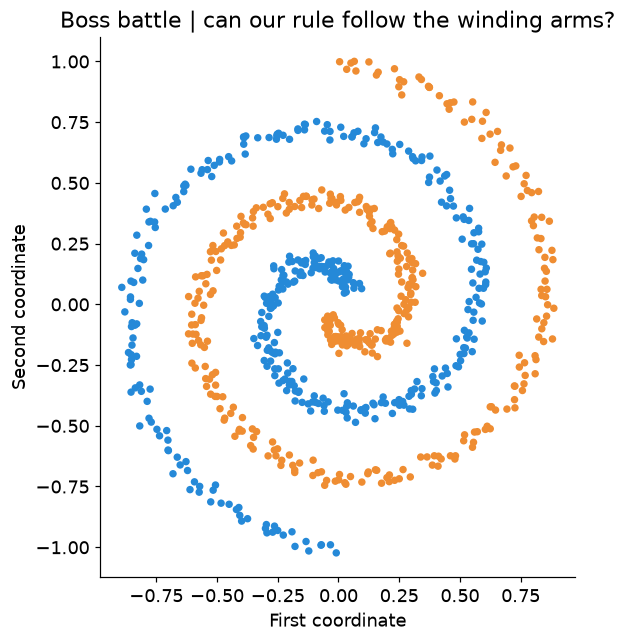

In [64]:
rng = np.random.default_rng(303)
radius = np.linspace(0.08, 1.0, 400)
angle = radius * 3.5 * np.pi
arm = np.column_stack([radius * np.cos(angle), radius * np.sin(angle)])
spiral_X = np.vstack([arm, -arm]) + rng.normal(0, 0.025, (800, 2))
spiral_y = np.repeat([0, 1], 400)
sx_fit, sx_test, sy_fit, sy_test = train_test_split(spiral_X, spiral_y, test_size=0.2, random_state=303, stratify=spiral_y)
sx_train, sx_val, sy_train, sy_val = train_test_split(sx_fit, sy_fit, test_size=0.25, random_state=303, stratify=sy_fit)
SX = torch.tensor(sx_train, dtype=torch.float32)
SY = torch.tensor(sy_train, dtype=torch.float32).reshape(-1, 1)
VX = torch.tensor(sx_val, dtype=torch.float32)
VY = torch.tensor(sy_val, dtype=torch.float32).reshape(-1, 1)
TX = torch.tensor(sx_test, dtype=torch.float32)
TY = torch.tensor(sy_test, dtype=torch.float32).reshape(-1, 1)
sgx, sgy = np.meshgrid(np.linspace(-1.2, 1.2, 100), np.linspace(-1.2, 1.2, 100))
sgrid = torch.tensor(np.column_stack([sgx.ravel(), sgy.ravel()]), dtype=torch.float32)
fig, ax = plt.subplots(figsize=(7, 6))
ax.scatter(spiral_X[:, 0], spiral_X[:, 1], c=spiral_y, cmap=cmap, s=15)
ax.set(title='Boss battle | can our rule follow the winding arms?', xlabel='First coordinate', ylabel='Second coordinate', aspect='equal')
fig.tight_layout()
fig.savefig(ROOT / 'visuals/spiral_data.png', dpi=180)
plt.show()

In [65]:
torch.manual_seed(404)
spiral_baseline = make_network(16)
baseline_trace = fit(spiral_baseline, torch.optim.Adam(spiral_baseline.parameters(), lr=0.01), SX, SY, epochs=800, query=None)
results['spiral_baseline'] = {'train': metrics(spiral_baseline, SX, SY), 'test': metrics(spiral_baseline, TX, TY)}
def spiral_network():
    return nn.Sequential(nn.Linear(2, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 64), nn.ReLU(), nn.Linear(64, 1))
torch.manual_seed(505)
spiral_initial = copy.deepcopy(spiral_network().state_dict())
rate_grid = {'SGD': [0.03, 0.1, 0.3], 'Momentum': [0.03, 0.1, 0.3], 'Adam': [0.001, 0.003, 0.01]}
spiral_models, spiral_traces, trials = {}, {}, []
for name, rates in rate_grid.items():
    best_loss = float('inf')
    for rate in rates:
        model = spiral_network()
        model.load_state_dict(spiral_initial)
        if name == 'Adam':
            optimizer = torch.optim.Adam(model.parameters(), lr=rate)
        else:
            momentum = 0.9 if name == 'Momentum' else 0.0
            optimizer = torch.optim.SGD(model.parameters(), lr=rate, momentum=momentum)
        trace = fit(model, optimizer, SX, SY, epochs=800, query=None)
        validation = metrics(model, VX, VY)
        trials.append({'optimizer': name, 'lr': rate, 'validation_loss': validation['loss'], 'validation_accuracy': validation['accuracy']})
        if validation['loss'] < best_loss:
            best_loss = validation['loss']
            spiral_models[name], spiral_traces[name] = model, trace
            chosen_rate = rate
    results[f'spiral_{name}'] = {'lr': chosen_rate, 'validation_loss': best_loss, 'train': metrics(spiral_models[name], SX, SY), 'test': metrics(spiral_models[name], TX, TY)}
print('Baseline:', results['spiral_baseline'])
print(json.dumps(trials, indent=2))

Baseline: {'train': {'loss': 0.0009930651867762208, 'accuracy': 1.0}, 'test': {'loss': 0.0021424603182822466, 'accuracy': 1.0}}
[
  {
    "optimizer": "SGD",
    "lr": 0.03,
    "validation_loss": 0.6708170771598816,
    "validation_accuracy": 0.6312500238418579
  },
  {
    "optimizer": "SGD",
    "lr": 0.1,
    "validation_loss": 0.6637556552886963,
    "validation_accuracy": 0.6000000238418579
  },
  {
    "optimizer": "SGD",
    "lr": 0.3,
    "validation_loss": 0.3711817264556885,
    "validation_accuracy": 0.8125
  },
  {
    "optimizer": "Momentum",
    "lr": 0.03,
    "validation_loss": 0.01649390533566475,
    "validation_accuracy": 1.0
  },
  {
    "optimizer": "Momentum",
    "lr": 0.1,
    "validation_loss": 0.002254561521112919,
    "validation_accuracy": 1.0
  },
  {
    "optimizer": "Momentum",
    "lr": 0.3,
    "validation_loss": 0.0005549668567255139,
    "validation_accuracy": 1.0
  },
  {
    "optimizer": "Adam",
    "lr": 0.001,
    "validation_loss": 0.00065373873

SGD {'lr': 0.3, 'validation_loss': 0.3711817264556885, 'train': {'loss': 0.33452752232551575, 'accuracy': 0.84375}, 'test': {'loss': 0.4005628228187561, 'accuracy': 0.7562500238418579}}
Momentum {'lr': 0.3, 'validation_loss': 0.0005549668567255139, 'train': {'loss': 0.00013507198309525847, 'accuracy': 1.0}, 'test': {'loss': 0.0003003940510097891, 'accuracy': 1.0}}
Adam {'lr': 0.01, 'validation_loss': 0.00011303846258670092, 'train': {'loss': 1.6302783478749916e-05, 'accuracy': 1.0}, 'test': {'loss': 4.896209065918811e-05, 'accuracy': 1.0}}


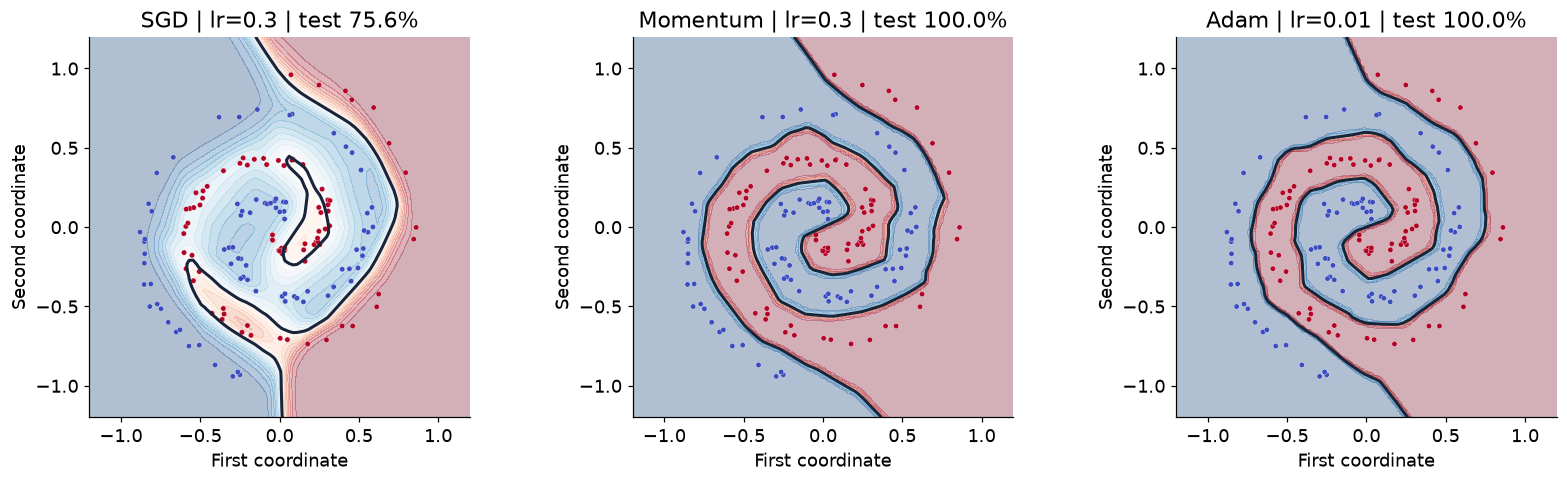

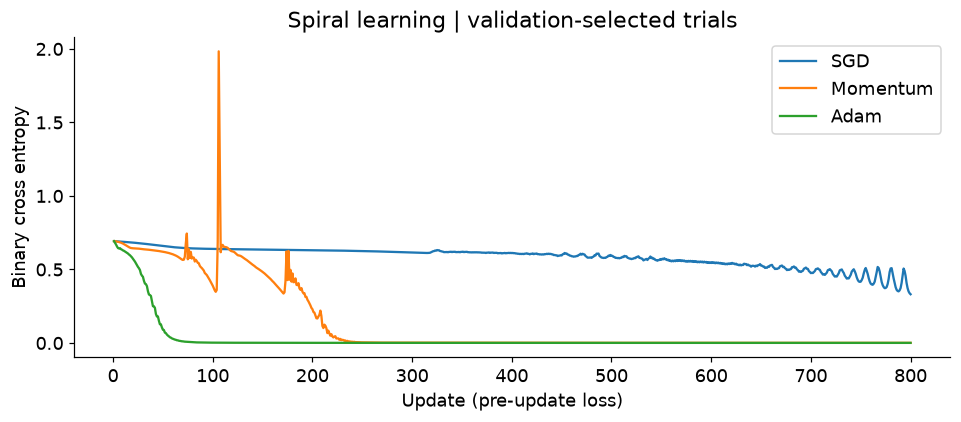

In [66]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, name in zip(axes, rate_grid):
    record = results[f'spiral_{name}']
    boundary(ax, spiral_models[name], sx_test, sy_test, f"{name} | lr={record['lr']} | test {record['test']['accuracy']:.1%}", (sgx, sgy), sgrid)
    print(name, record)
fig.tight_layout()
fig.savefig(ROOT / 'visuals/spiral_comparison.png', dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
for name, trace in spiral_traces.items():
    ax.plot(np.arange(1, 801), trace['loss'], label=name)
ax.set(xlabel='Update (pre-update loss)', ylabel='Binary cross entropy', title='Spiral learning | validation-selected trials')
ax.legend()
fig.tight_layout()
fig.savefig(ROOT / 'visuals/spiral_losses.png', dpi=180)
plt.show()

8 {'epoch': 1600, 'train': {'loss': 0.2495667040348053, 'accuracy': 0.8916666507720947}, 'test': {'loss': 0.4585898220539093, 'accuracy': 0.8785714507102966}}
128 {'epoch': 1600, 'train': {'loss': 0.0010176015784963965, 'accuracy': 1.0}, 'test': {'loss': 2.294078826904297, 'accuracy': 0.8571428656578064}}


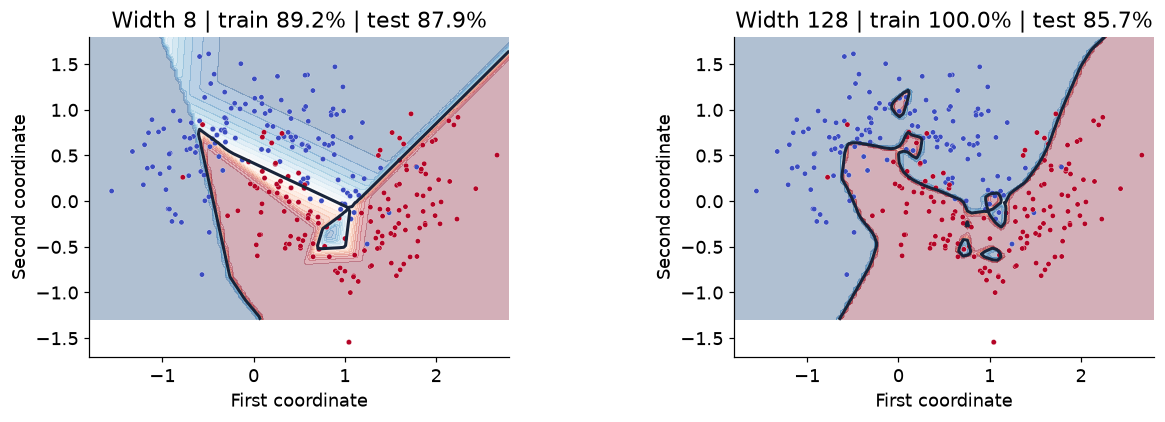

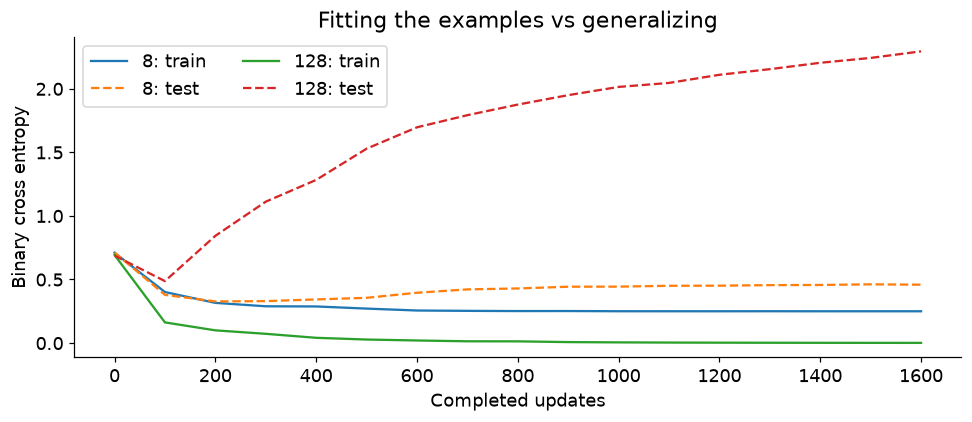

In [67]:
noisy_X, noisy_y = make_moons(n_samples=400, noise=0.32, random_state=606)
nx_train, nx_test, ny_train, ny_test = train_test_split(noisy_X, noisy_y, train_size=120, random_state=606, stratify=noisy_y)
NX = torch.tensor(nx_train, dtype=torch.float32)
NY = torch.tensor(ny_train, dtype=torch.float32).reshape(-1, 1)
NXT = torch.tensor(nx_test, dtype=torch.float32)
NYT = torch.tensor(ny_test, dtype=torch.float32).reshape(-1, 1)
overfit_curves = {}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, width in zip(axes, [8, 128]):
    torch.manual_seed(707)
    model = make_network(width)
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    curve = []
    for checkpoint in range(17):
        curve.append({'epoch': checkpoint * 100, 'train': metrics(model, NX, NY), 'test': metrics(model, NXT, NYT)})
        if checkpoint < 16:
            fit(model, optimizer, NX, NY, epochs=100, query=None)
    overfit_curves[str(width)] = curve
    results[f'noisy_{width}'] = curve[-1]
    boundary(ax, model, nx_test, ny_test, f"Width {width} | train {curve[-1]['train']['accuracy']:.1%} | test {curve[-1]['test']['accuracy']:.1%}")
    print(width, curve[-1])
fig.tight_layout()
fig.savefig(ROOT / 'visuals/overfitting_boundaries.png', dpi=180)
plt.show()
fig, ax = plt.subplots(figsize=(9, 4))
for width, curve in overfit_curves.items():
    ax.plot([p['epoch'] for p in curve], [p['train']['loss'] for p in curve], label=f'{width}: train')
    ax.plot([p['epoch'] for p in curve], [p['test']['loss'] for p in curve], '--', label=f'{width}: test')
ax.set(xlabel='Completed updates', ylabel='Binary cross entropy', title='Fitting the examples vs generalizing')
ax.legend(ncol=2)
fig.tight_layout()
fig.savefig(ROOT / 'visuals/overfitting_curves.png', dpi=180)
plt.show()

In [68]:
elapsed = time.perf_counter() - started
evidence = {'versions': versions, 'runtime_seconds': elapsed, 'results': results, 'spiral_trials': trials, 'overfit_curves': overfit_curves, 'model_c_frame_epochs': trace_c['epochs'], 'affine_collapse_max_error': error}
(ROOT / 'validation/executed_results.json').write_text(json.dumps(evidence, indent=2), encoding='utf8')
print(f'CPU session completed in {elapsed:.1f} seconds.')
print('Evidence saved to:', ROOT / 'validation/executed_results.json')
assert len(trace_c['frames']) == 41
assert all(p.device.type == 'cpu' for p in model_c.parameters())

CPU session completed in 392.9 seconds.
Evidence saved to: c:\Users\AIML\pytorch_from_basics\optimizer_step_pytorch_episode_03\validation\executed_results.json
